In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

#### 1. Data Import

In [2]:
df = pd.read_csv("wbcd.csv")

In [3]:
df.shape

(569, 32)

In [4]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,points_worst,symmetry_worst,dimension_worst
0,87139402,B,12.32,12.39,78.85,464.1,0.10280,0.06981,0.03987,0.03700,...,13.50,15.64,86.97,549.1,0.1385,0.1266,0.12420,0.09391,0.2827,0.06771
1,8910251,B,10.60,18.95,69.28,346.4,0.09688,0.11470,0.06387,0.02642,...,11.88,22.94,78.28,424.8,0.1213,0.2515,0.19160,0.07926,0.2940,0.07587
2,905520,B,11.04,16.83,70.92,373.2,0.10770,0.07804,0.03046,0.02480,...,12.41,26.44,79.93,471.4,0.1369,0.1482,0.10670,0.07431,0.2998,0.07881
3,868871,B,11.28,13.39,73.00,384.8,0.11640,0.11360,0.04635,0.04796,...,11.92,15.77,76.53,434.0,0.1367,0.1822,0.08669,0.08611,0.2102,0.06784
4,9012568,B,15.19,13.21,97.65,711.8,0.07963,0.06934,0.03393,0.02657,...,16.20,15.73,104.50,819.1,0.1126,0.1737,0.13620,0.08178,0.2487,0.06766


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 569 non-null    int64  
 1   diagnosis          569 non-null    object 
 2   radius_mean        569 non-null    float64
 3   texture_mean       569 non-null    float64
 4   perimeter_mean     569 non-null    float64
 5   area_mean          569 non-null    float64
 6   smoothness_mean    569 non-null    float64
 7   compactness_mean   569 non-null    float64
 8   concavity_mean     569 non-null    float64
 9   points_mean        569 non-null    float64
 10  symmetry_mean      569 non-null    float64
 11  dimension_mean     569 non-null    float64
 12  radius_se          569 non-null    float64
 13  texture_se         569 non-null    float64
 14  perimeter_se       569 non-null    float64
 15  area_se            569 non-null    float64
 16  smoothness_se      569 non

In [6]:
df.isnull().sum().sort_values()

id                   0
points_worst         0
concavity_worst      0
compactness_worst    0
smoothness_worst     0
area_worst           0
perimeter_worst      0
texture_worst        0
radius_worst         0
dimension_se         0
symmetry_se          0
points_se            0
concavity_se         0
compactness_se       0
smoothness_se        0
area_se              0
perimeter_se         0
texture_se           0
radius_se            0
dimension_mean       0
symmetry_mean        0
points_mean          0
concavity_mean       0
compactness_mean     0
smoothness_mean      0
area_mean            0
perimeter_mean       0
texture_mean         0
radius_mean          0
diagnosis            0
symmetry_worst       0
dimension_worst      0
dtype: int64

In [7]:
print(df.duplicated().sum())

0


#### 2. Data Cleaning & Preparation 

#### 3. Data Splitting

In [8]:
df.columns

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'points_mean', 'symmetry_mean', 'dimension_mean', 'radius_se',
       'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'points_se', 'symmetry_se',
       'dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst',
       'area_worst', 'smoothness_worst', 'compactness_worst',
       'concavity_worst', 'points_worst', 'symmetry_worst', 'dimension_worst'],
      dtype='object')

In [9]:
x = df.iloc[:, 2:]
x.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,points_mean,symmetry_mean,dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,points_worst,symmetry_worst,dimension_worst
0,12.32,12.39,78.85,464.1,0.10280,0.06981,0.03987,0.03700,0.1959,0.05955,...,13.50,15.64,86.97,549.1,0.1385,0.1266,0.12420,0.09391,0.2827,0.06771
1,10.60,18.95,69.28,346.4,0.09688,0.11470,0.06387,0.02642,0.1922,0.06491,...,11.88,22.94,78.28,424.8,0.1213,0.2515,0.19160,0.07926,0.2940,0.07587
2,11.04,16.83,70.92,373.2,0.10770,0.07804,0.03046,0.02480,0.1714,0.06340,...,12.41,26.44,79.93,471.4,0.1369,0.1482,0.10670,0.07431,0.2998,0.07881
3,11.28,13.39,73.00,384.8,0.11640,0.11360,0.04635,0.04796,0.1771,0.06072,...,11.92,15.77,76.53,434.0,0.1367,0.1822,0.08669,0.08611,0.2102,0.06784
4,15.19,13.21,97.65,711.8,0.07963,0.06934,0.03393,0.02657,0.1721,0.05544,...,16.20,15.73,104.50,819.1,0.1126,0.1737,0.13620,0.08178,0.2487,0.06766


In [10]:
y = df.iloc[:, 1]
y.head()

0    B
1    B
2    B
3    B
4    B
Name: diagnosis, dtype: object

In [11]:
trainx, testx, trainy, testy = train_test_split(x, y, test_size=50, shuffle=True, random_state=5, stratify=y)

In [12]:
print(df.shape)
print(trainx.shape)
print(testx.shape)
print(trainy.shape)
print(testy.shape)

(569, 32)
(519, 30)
(50, 30)
(519,)
(50,)


#### 4. Model Selection

In [13]:
from sklearn.tree import DecisionTreeClassifier as DTC
model = DTC(criterion="entropy")

#### 5.Model Training

In [14]:
model.fit(trainx, trainy)

,criterion,'entropy'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


#### 6.Prediction

In [15]:
predictions = model.predict(testx)
predictions[0:10]

array(['B', 'M', 'M', 'M', 'M', 'B', 'B', 'B', 'M', 'B'], dtype=object)

In [16]:
model.classes_

array(['B', 'M'], dtype=object)

#### 7. Model Evaluation

In [17]:
testy_array = testy.values.ravel()
accuracy = np.mean(predictions == testy_array)
print("Accuracy:", accuracy * 100)

Accuracy: 94.0


In [18]:
model.feature_importances_

array([0.        , 0.01395682, 0.        , 0.01313444, 0.        ,
       0.        , 0.00982469, 0.03356043, 0.00916611, 0.        ,
       0.        , 0.        , 0.        , 0.01729453, 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.0324141 , 0.07782031, 0.59765225, 0.01752601, 0.01223066,
       0.        , 0.        , 0.16541964, 0.        , 0.        ])

In [19]:
dict(sorted(zip(x.columns, model.feature_importances_),key=lambda item: item[1],reverse=True))

{'perimeter_worst': np.float64(0.5976522524499871),
 'points_worst': np.float64(0.16541963880967123),
 'texture_worst': np.float64(0.07782031424567343),
 'points_mean': np.float64(0.03356043379984308),
 'radius_worst': np.float64(0.03241410006493379),
 'area_worst': np.float64(0.017526010433799158),
 'area_se': np.float64(0.017294525480078083),
 'texture_mean': np.float64(0.013956823661946916),
 'area_mean': np.float64(0.013134438103063443),
 'smoothness_worst': np.float64(0.01223065885194505),
 'concavity_mean': np.float64(0.009824690586612686),
 'symmetry_mean': np.float64(0.009166113512445978),
 'radius_mean': np.float64(0.0),
 'perimeter_mean': np.float64(0.0),
 'smoothness_mean': np.float64(0.0),
 'compactness_mean': np.float64(0.0),
 'dimension_mean': np.float64(0.0),
 'radius_se': np.float64(0.0),
 'texture_se': np.float64(0.0),
 'perimeter_se': np.float64(0.0),
 'smoothness_se': np.float64(0.0),
 'compactness_se': np.float64(0.0),
 'concavity_se': np.float64(0.0),
 'points_se':

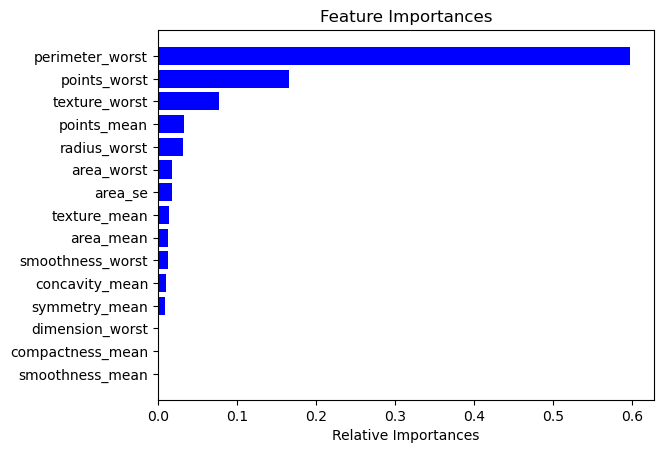

In [20]:
features = x.columns
importances = model.feature_importances_
indices = np.argsort(importances)[-15:]
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], color='b', align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importances')
plt.show()

#### Confusion Matrix

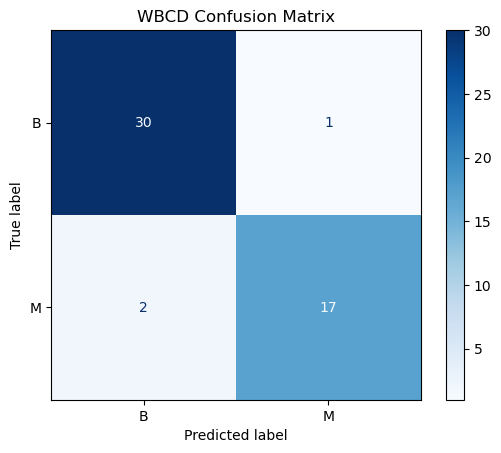

In [21]:
cm = confusion_matrix(testy, predictions, labels=['B', 'M'])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["B", "M"]
)

disp.plot(cmap="Blues")
plt.title("WBCD Confusion Matrix")
plt.show()

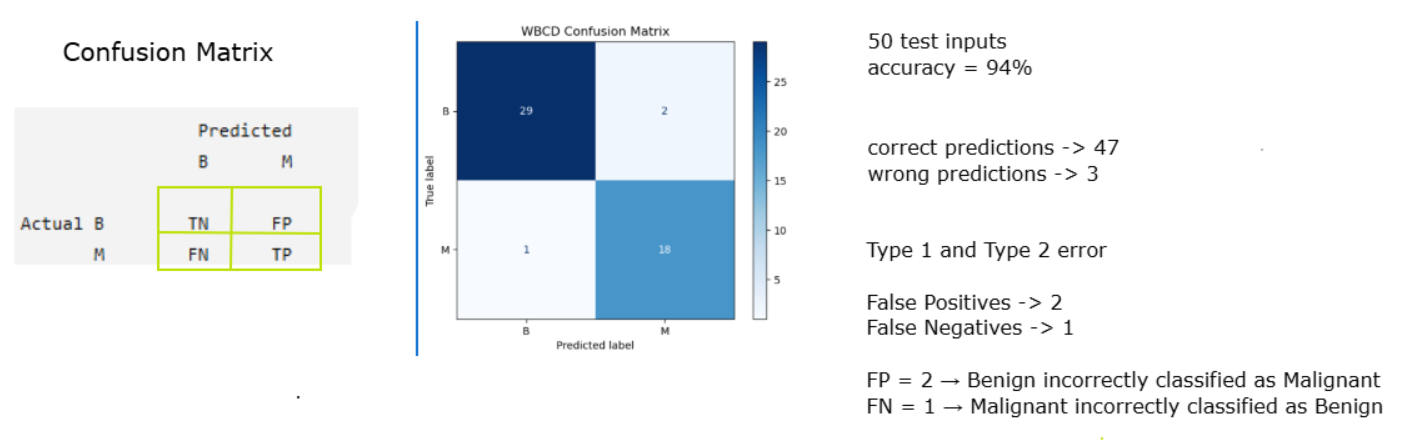

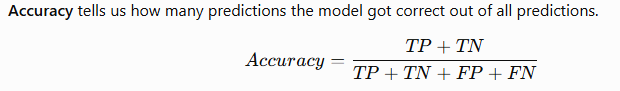

In [22]:
accuracy = accuracy_score(testy, predictions)
accuracy*100

94.0

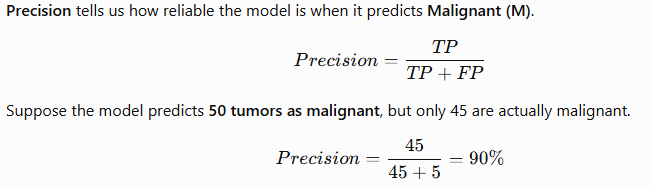

In [23]:
precision = precision_score(testy, predictions, pos_label='M')
print(f"Precision %: {precision * 100:.2f}")

Precision %: 94.44
